# Ejercicio pandas estadística
Para este ejercicio se ha utilizado [un dataset de un concurso de kaggle](https://www.kaggle.com/nickhould/craft-cans), cuyo reto consiste en predecir el tipo de cerveza en función de sus características (nivel de alcohol, amargura, tamaño...).

# Ejercicio 1
Importa las librerias que consideres

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

## Ejercicio 2
1. Importa el dataset "datasets_beer.csv"
2. Imprime por pantalla los primeros registros.
3. ¿Cuáles son sus columnas?
4. ¿Qué dimensiones tiene el DataFrame?

In [11]:
# 1. 
beers = pd.read_csv('data/datasets_beers.csv')

# 2. 
print(beers.head())
print()

# 3. 
print(beers.columns)
print()

# 4. 
print(beers.shape)


   Unnamed: 0    abv  ibu    id                 name  \
0           0  0.050  NaN  1436             Pub Beer   
1           1  0.066  NaN  2265          Devil's Cup   
2           2  0.071  NaN  2264  Rise of the Phoenix   
3           3  0.090  NaN  2263             Sinister   
4           4  0.075  NaN  2262        Sex and Candy   

                            style  brewery_id  ounces  
0             American Pale Lager         408    12.0  
1         American Pale Ale (APA)         177    12.0  
2                    American IPA         177    12.0  
3  American Double / Imperial IPA         177    12.0  
4                    American IPA         177    12.0  

Index(['Unnamed: 0', 'abv', 'ibu', 'id', 'name', 'style', 'brewery_id',
       'ounces'],
      dtype='object')

(2410, 8)


## Ejercicio 3
[Elimina la columna "Unnamed: 0"](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.drop.html)

In [12]:
beers.drop(columns='Unnamed: 0', inplace=True)

In [13]:
# Para guardar el dataframe en un csv: 
beers.to_csv('prueba.csv', index=False)

## Ejercicio 4
¿Cuántas filas y columnas tiene el dataset?

In [14]:
beers.shape

(2410, 7)

## Ejercicio 5
¿De qué tipo son los datos?

In [15]:
# beers.info()
beers.dtypes

abv           float64
ibu           float64
id              int64
name           object
style          object
brewery_id      int64
ounces        float64
dtype: object

## Ejercicio 6
Obtén en un nuevo DataFrame un resumen con las principales estadísticas de las columnas numéricas: mean, max, count, cuartiles...

In [16]:
beers_res = beers.describe()
beers_res

,abv,ibu,id,brewery_id,ounces
count,2348.000000,1405.000000,2410.000000,2410.000000,2410.000000
mean,0.059773,42.713167,1431.113278,231.749793,13.592241
std,0.013542,25.954066,752.459975,157.685604,2.352204
min,0.001000,4.000000,1.000000,0.000000,8.400000
25%,0.050000,21.000000,808.250000,93.000000,12.000000
50%,0.056000,35.000000,1453.500000,205.000000,12.000000
75%,0.067000,64.000000,2075.750000,366.000000,16.000000
max,0.128000,138.000000,2692.000000,557.000000,32.000000


## Ejercicio 7
¿Cuántas birras hay de cada estilo en este dataset? [Investiga en la documentación de Series](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.html) si puedes hacer un conteo de valores.

In [17]:
beers['style'].value_counts()

style
American IPA                      424
American Pale Ale (APA)           245
American Amber / Red Ale          133
American Blonde Ale               108
American Double / Imperial IPA    105
                                 ... 
American Malt Liquor                1
Wheat Ale                           1
Flanders Red Ale                    1
Kristalweizen                       1
Low Alcohol Beer                    1
Name: count, Length: 99, dtype: int64

In [18]:
beers['style'].unique()

array(['American Pale Lager', 'American Pale Ale (APA)', 'American IPA',
       'American Double / Imperial IPA', 'Oatmeal Stout',
       'American Porter', 'Saison / Farmhouse Ale', 'Belgian IPA',
       'Cider', 'Baltic Porter', 'Tripel', 'American Barleywine',
       'Winter Warmer', 'American Stout', 'Fruit / Vegetable Beer',
       'English Strong Ale', 'American Black Ale', 'Belgian Dark Ale',
       'American Blonde Ale', 'American Amber / Red Ale',
       'Berliner Weissbier', 'American Brown Ale',
       'American Pale Wheat Ale', 'Belgian Strong Dark Ale', 'Kölsch',
       'English Pale Ale', 'American Amber / Red Lager',
       'English Barleywine', 'Milk / Sweet Stout', 'German Pilsener',
       'Pumpkin Ale', 'Belgian Pale Ale', 'American Pilsner',
       'American Wild Ale', 'English Brown Ale', 'Altbier',
       'California Common / Steam Beer', 'Gose', 'Cream Ale',
       'Vienna Lager', 'Witbier', 'American Double / Imperial Stout',
       'Munich Helles Lager', 'Schwa

## Ejercicio 8
1. Imprime por pantalla los registros desde el décimo hasta el vigésimo
2. De esos registros, imprime por pantalla desde la columna `name` a `ounces`, ambas incluidas
3. Quédate con las columnas `abv`, `ibu` y `ounces`, y además quédate sólo con los registros 10 al 20.
4. Convierte el resultado del apartado 3 en un array de `numpy`

In [19]:
# 1. 
beers_10a20 = beers[10:20]
print(beers_10a20)
print()

# 2. 
print(beers_10a20.loc[:, 'name':'ounces'])
print()

# 3. 
beers_slc = beers.loc[10:20, ['abv', 'ibu', 'ounces']]
print(beers_slc)
print()

# 4. 
beers_slc_np = beers_slc.to_numpy()
print(beers_slc_np)
print()

      abv   ibu    id                         name                    style  \
10  0.072   NaN  2099            Sophomoric Saison   Saison / Farmhouse Ale   
11  0.073   NaN  2098        Regional Ring Of Fire   Saison / Farmhouse Ale   
12  0.069   NaN  2097                   Garce Selé   Saison / Farmhouse Ale   
13  0.085   NaN  1980              Troll Destroyer              Belgian IPA   
14  0.061  60.0  1979                 Bitter Bitch  American Pale Ale (APA)   
15  0.060   NaN  2318                  Ginja Ninja                    Cider   
16  0.060   NaN  2170                Cherried Away                    Cider   
17  0.060   NaN  2169                 Rhubarbarian                    Cider   
18  0.060   NaN  1502                  BrightCider                    Cider   
19  0.082   NaN  1593  He Said Baltic-Style Porter            Baltic Porter   

    brewery_id  ounces  
10         177    12.0  
11         177    12.0  
12         177    12.0  
13         177    12.0  
14   

## Ejercicio 9
¿Cuántas onzas pesan todas las birras del dataset?

In [20]:
print(beers['ounces'].sum())

32757.3


## Ejercicio 10
El amargor de las cervezas se mide por su nivel de IBUs.
1. ¿Cuál es el amargor medio de las cervezas?
2. ¿El máximo? ¿Y el mínimo?
3. ¿Qué cerveza es la que tiene el amargor máximo? ¿Cuál es la de amargor mínimo?

In [22]:
# 1. 
print(beers['ibu'].mean())
print()

# 2. 
print(f"Amargor máximo: {beers['ibu'].max()}")
print(f"Amargor mínimo: {beers['ibu'].min()}")
print()

# 3. 
print(f"Cerveza de amargor máximo: {beers['name'][beers['ibu'].idxmax()]}")
print(f"Cerveza de amargor mínimo: {beers['name'][beers['ibu'].idxmin()]}")
# Mejor así, por si hay varias cervezas que tengan los máximos/mínimos valores: 
beers[beers['ibu'] == beers['ibu'].max()]
beers[beers['ibu'] == beers['ibu'].min()]

# print(beers.nunique())

42.71316725978647

Amargor máximo: 138.0
Amargor mínimo: 4.0

Cerveza de amargor máximo: Bitter Bitch Imperial IPA
Cerveza de amargor mínimo: Summer Solstice


,abv,ibu,id,name,style,brewery_id,ounces
106,0.056,4.0,1350,Summer Solstice,Cream Ale,171,12.0
112,0.056,4.0,753,Summer Solstice Cerveza Crema (2009),Cream Ale,171,12.0
117,0.056,4.0,77,Summer Solstice (2011),Cream Ale,171,12.0


## Ejercicio 11
No queda muy claro cuánto de dispar, de dispersa, es la medida de IBU. Mediante estadística descriptiva (una o dos métricas, sin gráficas), razona la dispersión de la variable IBU.

In [11]:
beers['ibu'].describe()

count    1405.000000
mean       42.713167
std        25.954066
min         4.000000
25%        21.000000
50%        35.000000
75%        64.000000
max       138.000000
Name: ibu, dtype: float64

## Ejercicio 12
¿Existe alguna relación lineal entre las variables numéricas del dataset? Intenta pintar este razonamiento mediante un gráfico

<Axes: >

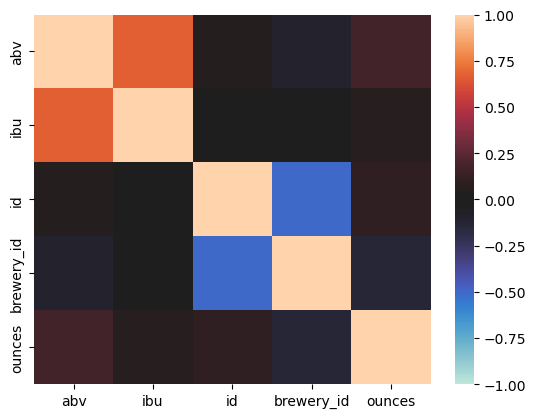

In [12]:
# beers.corr(numeric_only=True)
sns.heatmap(beers.corr(numeric_only=True), vmin=-1, vmax=1, center=0)

<Axes: xlabel='abv', ylabel='ibu'>

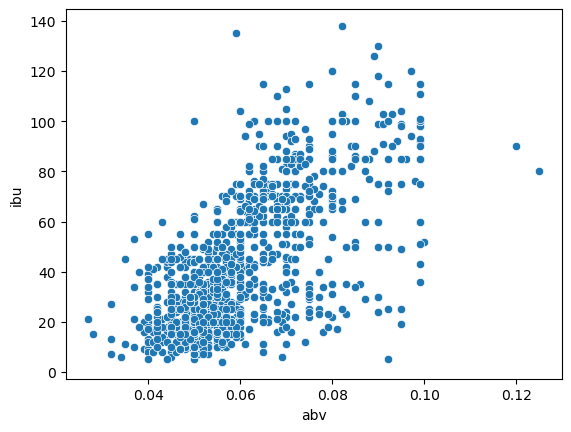

In [13]:
sns.scatterplot(x = beers['abv'], y = beers['ibu'])

In [14]:
# sns.scatterplot(x = beers['id'], y = beers['brewery_id'])

## Ejercicio 13
Representa el nivel de alcohol (columna `abv`) en un histograma. ¿Se trata de una distribución simétrica o asimétrica?

Se trata de una distribución asimétrica (asimetría positiva). CAF = 0.9578647103102429


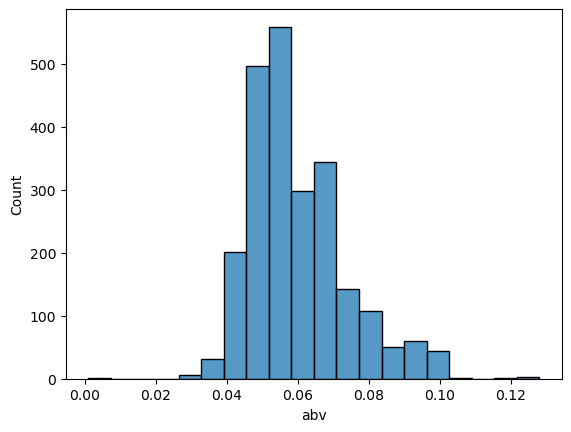

In [15]:
sns.histplot(beers['abv'], bins=20)
# beers.info()
print(f"Se trata de una distribución asimétrica (asimetría positiva). CAF = {stats.skew(beers['abv'].dropna())}")

## Ejercicio 14
Representa mediante un *boxplot* de `seaborn` la variable `abv`

<Axes: >

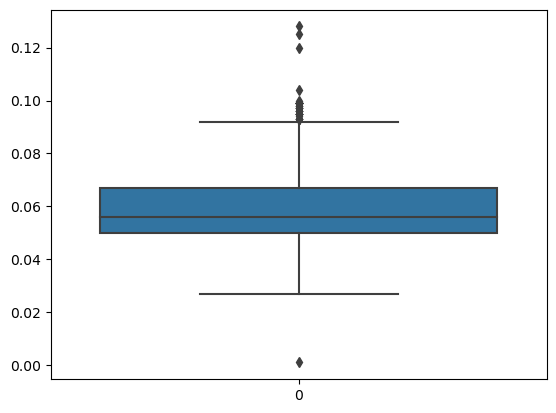

In [16]:
sns.boxplot(beers['abv'])

## Ejercicio 15
1. ¿Qué estilos son los que tienen en media más alcohol?
2. ¿Y los estilos que son en media más amargos?

In [17]:
# 1. 
print(beers.groupby('style')['abv'].mean().idxmax())
# beers.groupby('style')['abv'].mean().sort_values(ascending=False)

# 2. 
print(beers.groupby('style')['ibu'].mean().idxmax())
# beers.groupby('style')['ibu'].mean().sort_values(ascending=False)

English Barleywine
American Barleywine


## Ejercicio 16
Carga el datasets de cervecerias `datasets_breweries.csv`

In [18]:
breweries = pd.read_csv('data/datasets_breweries.csv')
breweries

,Unnamed: 0,name,city,state
0,0,NorthGate Brewing,Minneapolis,MN
1,1,Against the Grain Brewery,Louisville,KY
2,2,Jack's Abby Craft Lagers,Framingham,MA
3,3,Mike Hess Brewing Company,San Diego,CA
4,4,Fort Point Beer Company,San Francisco,CA
...,...,...,...,...
553,553,Covington Brewhouse,Covington,LA
554,554,Dave's Brewfarm,Wilson,WI
555,555,Ukiah Brewing Company,Ukiah,CA
556,556,Butternuts Beer and Ale,Garrattsville,NY


## Ejercicio 17
1. Renombra la columna `Unnamed: 0` como `brewery_id`
2. Renombra también la columna `name` por `brewery_name`. ¿Puedes hacer ambos apartados en una sola sentencia?

In [19]:
breweries.rename(columns={'Unnamed: 0': 'brewery_id', 'name': 'brewery_name'}, inplace=True)

## Ejercicio 18
Junta los dos datasets que tienes

In [20]:
beers_completo = pd.merge(beers, breweries, on='brewery_id')
beers_completo

,abv,ibu,id,name,style,brewery_id,ounces,brewery_name,city,state
0,0.050,NaN,1436,Pub Beer,American Pale Lager,408,12.0,10 Barrel Brewing Company,Bend,OR
1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0,18th Street Brewery,Gary,IN
2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0,18th Street Brewery,Gary,IN
3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0,18th Street Brewery,Gary,IN
4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0,18th Street Brewery,Gary,IN
...,...,...,...,...,...,...,...,...,...,...
2405,0.067,45.0,928,Belgorado,Belgian IPA,424,12.0,Wynkoop Brewing Company,Denver,CO
2406,0.052,NaN,807,Rail Yard Ale,American Amber / Red Ale,424,12.0,Wynkoop Brewing Company,Denver,CO
2407,0.055,NaN,620,B3K Black Lager,Schwarzbier,424,12.0,Wynkoop Brewing Company,Denver,CO
2408,0.055,40.0,145,Silverback Pale Ale,American Pale Ale (APA),424,12.0,Wynkoop Brewing Company,Denver,CO


## Ejercicio 19
1. ¿Cuántos estados diferentes hay?
2. ¿Y ciudades diferentes?
3. ¿Cuántas cervecerías hay?

In [21]:
# 1. 
print(f"Estados diferentes: {beers_completo['state'].nunique()}")

# 2. 
print(f"Ciudades diferentes: {beers_completo['city'].nunique()}")

# 3. 
# print(f"Nº de cervecerías: {beers_completo['brewery_name'].nunique()}")
# Hay cervecerías con el mismo nombre e ID distinto; son cervecerías distintas (en algunos casos, están en ciudades distintas)
print(f"Nº de cervecerías: {beers_completo['brewery_id'].nunique()}")
print(f"Nº de cervecerías: {beers['brewery_id'].nunique()}")
# beers_completo['brewery_id'].value_counts()
# beers_completo
# print(beers_completo.info())

Estados diferentes: 51
Ciudades diferentes: 384
Nº de cervecerías: 558
Nº de cervecerías: 558


## Ejercicio 20
Agrupa por estado y ciudad, la media, mediana y máximo nivel de alcohol

In [22]:
print(beers_completo.groupby(['state', 'city'])['abv'].aggregate(['mean', 'median', 'max']))
print(beers_completo.groupby(['state'])['abv'].aggregate(['mean', 'median', 'max']))

                      mean  median    max
state city                               
 AK   Anchorage   0.054200  0.0520  0.063
      Juneau      0.053000  0.0530  0.053
      Soldotna    0.058500  0.0580  0.068
      Talkeetna   0.059500  0.0585  0.065
 AL   Birmingham  0.065400  0.0600  0.093
...                    ...     ...    ...
 WI   Wilson      0.055000  0.0550  0.055
 WV   Lewisburg   0.062000  0.0620  0.067
 WY   Jackson     0.054857  0.0520  0.068
      Pinedale    0.061000  0.0610  0.072
      Sheridan    0.052833  0.0480  0.070

[401 rows x 3 columns]
           mean  median    max
state                         
 AK    0.055640  0.0560  0.068
 AL    0.062000  0.0600  0.093
 AR    0.052000  0.0520  0.061
 AZ    0.060227  0.0550  0.095
 CA    0.061082  0.0580  0.099
 CO    0.063372  0.0605  0.128
 CT    0.061074  0.0600  0.090
 DC    0.065625  0.0625  0.092
 DE    0.055000  0.0550  0.055
 FL    0.059946  0.0570  0.082
 GA    0.056375  0.0550  0.072
 HI    0.057296  0.0540  0.

## Ejercicio 21
¿Cuáles son las cervezas más amargas que se consumen en Indiana, estado = `IN`?

In [23]:
# ind = beers_completo.loc[beers_completo['state']==' IN', 'ibu'].idxmax()
# cerveza_mas_amarga_IN = beers_completo.loc[beers_completo['state']==' IN', 'name'][ind]
amargor_max_IN = beers_completo.loc[beers_completo['state']==' IN', 'ibu'].max()
cervezas_mas_amargas_IN = beers_completo.loc[(beers_completo['state']==' IN') & (beers_completo['ibu']==amargor_max_IN), 'name']
print(f'Cervezas más amargas que se consumen en Indiana: {cervezas_mas_amargas_IN.values}')

Cervezas más amargas que se consumen en Indiana: ['Hopkick Dropkick' 'Overlord Imperial IPA']


## Ejercicio 22
Obtén una tabla con los principales estadísticos del campo `ibu`,  a nivel ciudad

In [24]:
beers_completo.groupby('city')['ibu'].describe()

,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Abingdon,1.0,135.000000,NaN,135.0,135.00,135.0,135.00,135.0
Abita Springs,3.0,27.333333,21.455380,13.0,15.00,17.0,34.50,52.0
Ada,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Afton,4.0,43.000000,19.899749,22.0,28.00,45.0,60.00,60.0
Airway Heights,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
Woodinville,4.0,46.750000,18.643587,27.0,39.75,44.0,51.00,72.0
Worcester,1.0,69.000000,NaN,69.0,69.00,69.0,69.00,69.0
Yakima,2.0,54.000000,22.627417,38.0,46.00,54.0,62.00,70.0


## Ejercicio 23
Consigue en un DataFrame de todas las cervezas en cuyas cervecerías al menos haya una cerveza con un `abv` mínimo 0.07.

In [25]:
# msk = (beers_completo.groupby('brewery_id')['abv'].max() > 0.07)
max_abv_x_cervecerias = beers_completo.groupby(['brewery_id'])['abv'].aggregate(['max'])
msk = (max_abv_x_cervecerias > 0.07)
cervecerias_abv_min_gt_0p07 = max_abv_x_cervecerias[msk].dropna().index.to_numpy()
beers23 = beers_completo.loc[(beers_completo['brewery_id'].isin(cervecerias_abv_min_gt_0p07))]
beers23.head()


,abv,ibu,id,name,style,brewery_id,ounces,brewery_name,city,state
1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0,18th Street Brewery,Gary,IN
2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0,18th Street Brewery,Gary,IN
3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0,18th Street Brewery,Gary,IN
4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0,18th Street Brewery,Gary,IN
5,0.077,NaN,2261,Black Exodus,Oatmeal Stout,177,12.0,18th Street Brewery,Gary,IN


## Ejercicio 24
Teniendo en cuenta la media de amargor de todas las cervezas, obtén una tabla con las cervezas cuyos estados tengan una media de amargor en cerveza por encima de la media

In [26]:
amargor_med = beers['ibu'].mean()
med_ibu_x_estados = beers_completo.groupby(['state'])['ibu'].aggregate(['mean'])
msk = (med_ibu_x_estados > amargor_med)
estados_amargor_gt_med = med_ibu_x_estados[msk].dropna().index.to_numpy()
beers24 = beers_completo.loc[(beers_completo['state'].isin(estados_amargor_gt_med))]
beers24.head()

,abv,ibu,id,name,style,brewery_id,ounces,brewery_name,city,state
0,0.050,NaN,1436,Pub Beer,American Pale Lager,408,12.0,10 Barrel Brewing Company,Bend,OR
1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0,18th Street Brewery,Gary,IN
2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0,18th Street Brewery,Gary,IN
3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0,18th Street Brewery,Gary,IN
4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0,18th Street Brewery,Gary,IN
